In [1]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go

from hac.constants import POSITION_IDS
from hac.damit import DamitDataset


dataset = DamitDataset()

In [2]:
dataset[0]

{'model_id': 102,
 'asteroid_id': 101,
 'quality_flag': 4.0,
 'shape_path': PosixPath('/work3/projects/HAC-DTU/damit-20260809T000301Z/files/asteroid_101/model_102/shape.txt'),
 'mesh': <trimesh.Trimesh(vertices.shape=(402, 3), faces.shape=(800, 3))>,
 'camera_distance': 5.867228396617155,
 'lightcurves': {'0_hor1': {'intensity': array([1.02493159, 1.02556614, 1.02651419, 1.02724716, 1.02777504,
          1.02850943, 1.02866072, 1.02905913, 1.02917611, 1.0293575 ,
          1.02955386, 1.02961819, 1.02954974, 1.0292037 , 1.02922941,
          1.02920023, 1.02833887, 1.02842152, 1.02796938, 1.02759912,
          1.02748343, 1.02688764, 1.02734133, 1.02692832, 1.02718824,
          1.02710978, 1.02698861, 1.02698832, 1.02700703, 1.02718601,
          1.02700174, 1.02716424, 1.027626  , 1.02743413, 1.02784768,
          1.02801421, 1.02783719, 1.02799354, 1.02832818, 1.02836601,
          1.02851579, 1.02840183, 1.02896116, 1.0287689 , 1.02940572,
          1.02914176, 1.02951418, 1.028775

In [3]:
def get_damit_lc(
    dataset,
    index,
    cam_idx,
    curve_type="intensity",
):
    """
    Load or generate one simulated DAMIT lightcurve.

    Parameters
    ----------
    dataset : DamitDataset
        DAMIT dataset instance.

    index : int
        Dataset index.

    cam_idx : str
        Camera position ID, e.g. "45_top".

    curve_type : {"intensity", "binary"}
        Which simulated curve to return.

    Returns
    -------
    np.ndarray
        Simulated lightcurve.
    """
    if curve_type not in {"intensity", "binary"}:
        raise ValueError(
            "curve_type must be 'intensity' or 'binary'."
        )

    sample = dataset[index]

    return sample["lightcurves"][cam_idx][curve_type]

In [4]:
def plot_damit_lcs(
    dataset,
    index,
    cam_idx,
    *,
    curve_type="intensity",
    ncols=None,
    figsize_per_plot=(4.2, 2.4),
    sharex=True,
    sharey=False,
    max_cols=4,
):
    """
    Plot simulated DAMIT lightcurves for one or more camera positions.

    Parameters
    ----------
    dataset : DamitDataset
        DAMIT dataset instance.

    index : int
        Index into the DAMIT dataset.

    cam_idx : str or list-like[str]
        Single camera position ID, or multiple IDs such as POSITION_IDS.

    curve_type : {"intensity", "binary"}
        Type of simulated lightcurve.

    ncols : int | None
        Number of subplot columns. If None, selected automatically.

    figsize_per_plot : tuple[float, float]
        Width and height per subplot.

    sharex, sharey : bool
        Whether subplots share x/y axes.

    max_cols : int
        Maximum number of automatically selected columns.

    Returns
    -------
    tuple
        ``(fig, axes)``.
    """
    if isinstance(cam_idx, str):
        cam_indices = [cam_idx]
    else:
        cam_indices = list(cam_idx)

    if not cam_indices:
        raise ValueError(
            "cam_idx must contain at least one camera position."
        )

    if curve_type not in {"intensity", "binary"}:
        raise ValueError(
            "curve_type must be 'intensity' or 'binary'."
        )

    # Access once so the model is loaded and any missing lightcurves are
    # generated. This also gives us metadata for the figure title.
    sample = dataset[index]

    model_id = sample["model_id"]
    asteroid_id = sample["asteroid_id"]
    quality_flag = sample["quality_flag"]

    n = len(cam_indices)

    if ncols is None:
        ncols = min(
            max_cols,
            math.ceil(math.sqrt(n)),
        )

    nrows = math.ceil(
        n / ncols
    )

    fig_width = (
        figsize_per_plot[0]
        * ncols
    )

    fig_height = (
        figsize_per_plot[1]
        * nrows
    )

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(
            fig_width,
            fig_height,
        ),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )

    axes_flat = axes.ravel()

    for ax, cam in zip(
        axes_flat,
        cam_indices,
    ):
        lc = sample[
            "lightcurves"
        ][cam][curve_type]

        # 360 simulated frames correspond to angles 0..359 degrees.
        x = np.arange(
            len(lc),
            dtype=float,
        )

        ax.plot(
            x,
            lc,
            linewidth=1.5,
        )

        ax.set_title(
            f"cam {cam}",
            fontsize=10,
        )

        ax.grid(
            True,
            alpha=0.25,
        )

        ax.set_xlim(
            0,
            360,
        )

    # Hide unused subplot slots.
    for ax in axes_flat[n:]:
        ax.set_visible(
            False
        )

    # Add labels only to outer plots.
    for ax in axes[-1, :]:
        if ax.get_visible():
            ax.set_xlabel(
                "phase / angle [deg]"
            )

    for ax in axes[:, 0]:
        if ax.get_visible():
            ax.set_ylabel(
                curve_type
            )

    fig.suptitle(
        (
            f"DAMIT dataset index {index} | "
            f"asteroid_{asteroid_id} | "
            f"model_{model_id} | "
            f"quality={quality_flag:g} | "
            f"{curve_type}"
        ),
        fontsize=16,
        y=1.0,
    )

    fig.tight_layout(
        rect=(
            0,
            0,
            1,
            0.96,
        )
    )

    plt.show()

    return fig, axes

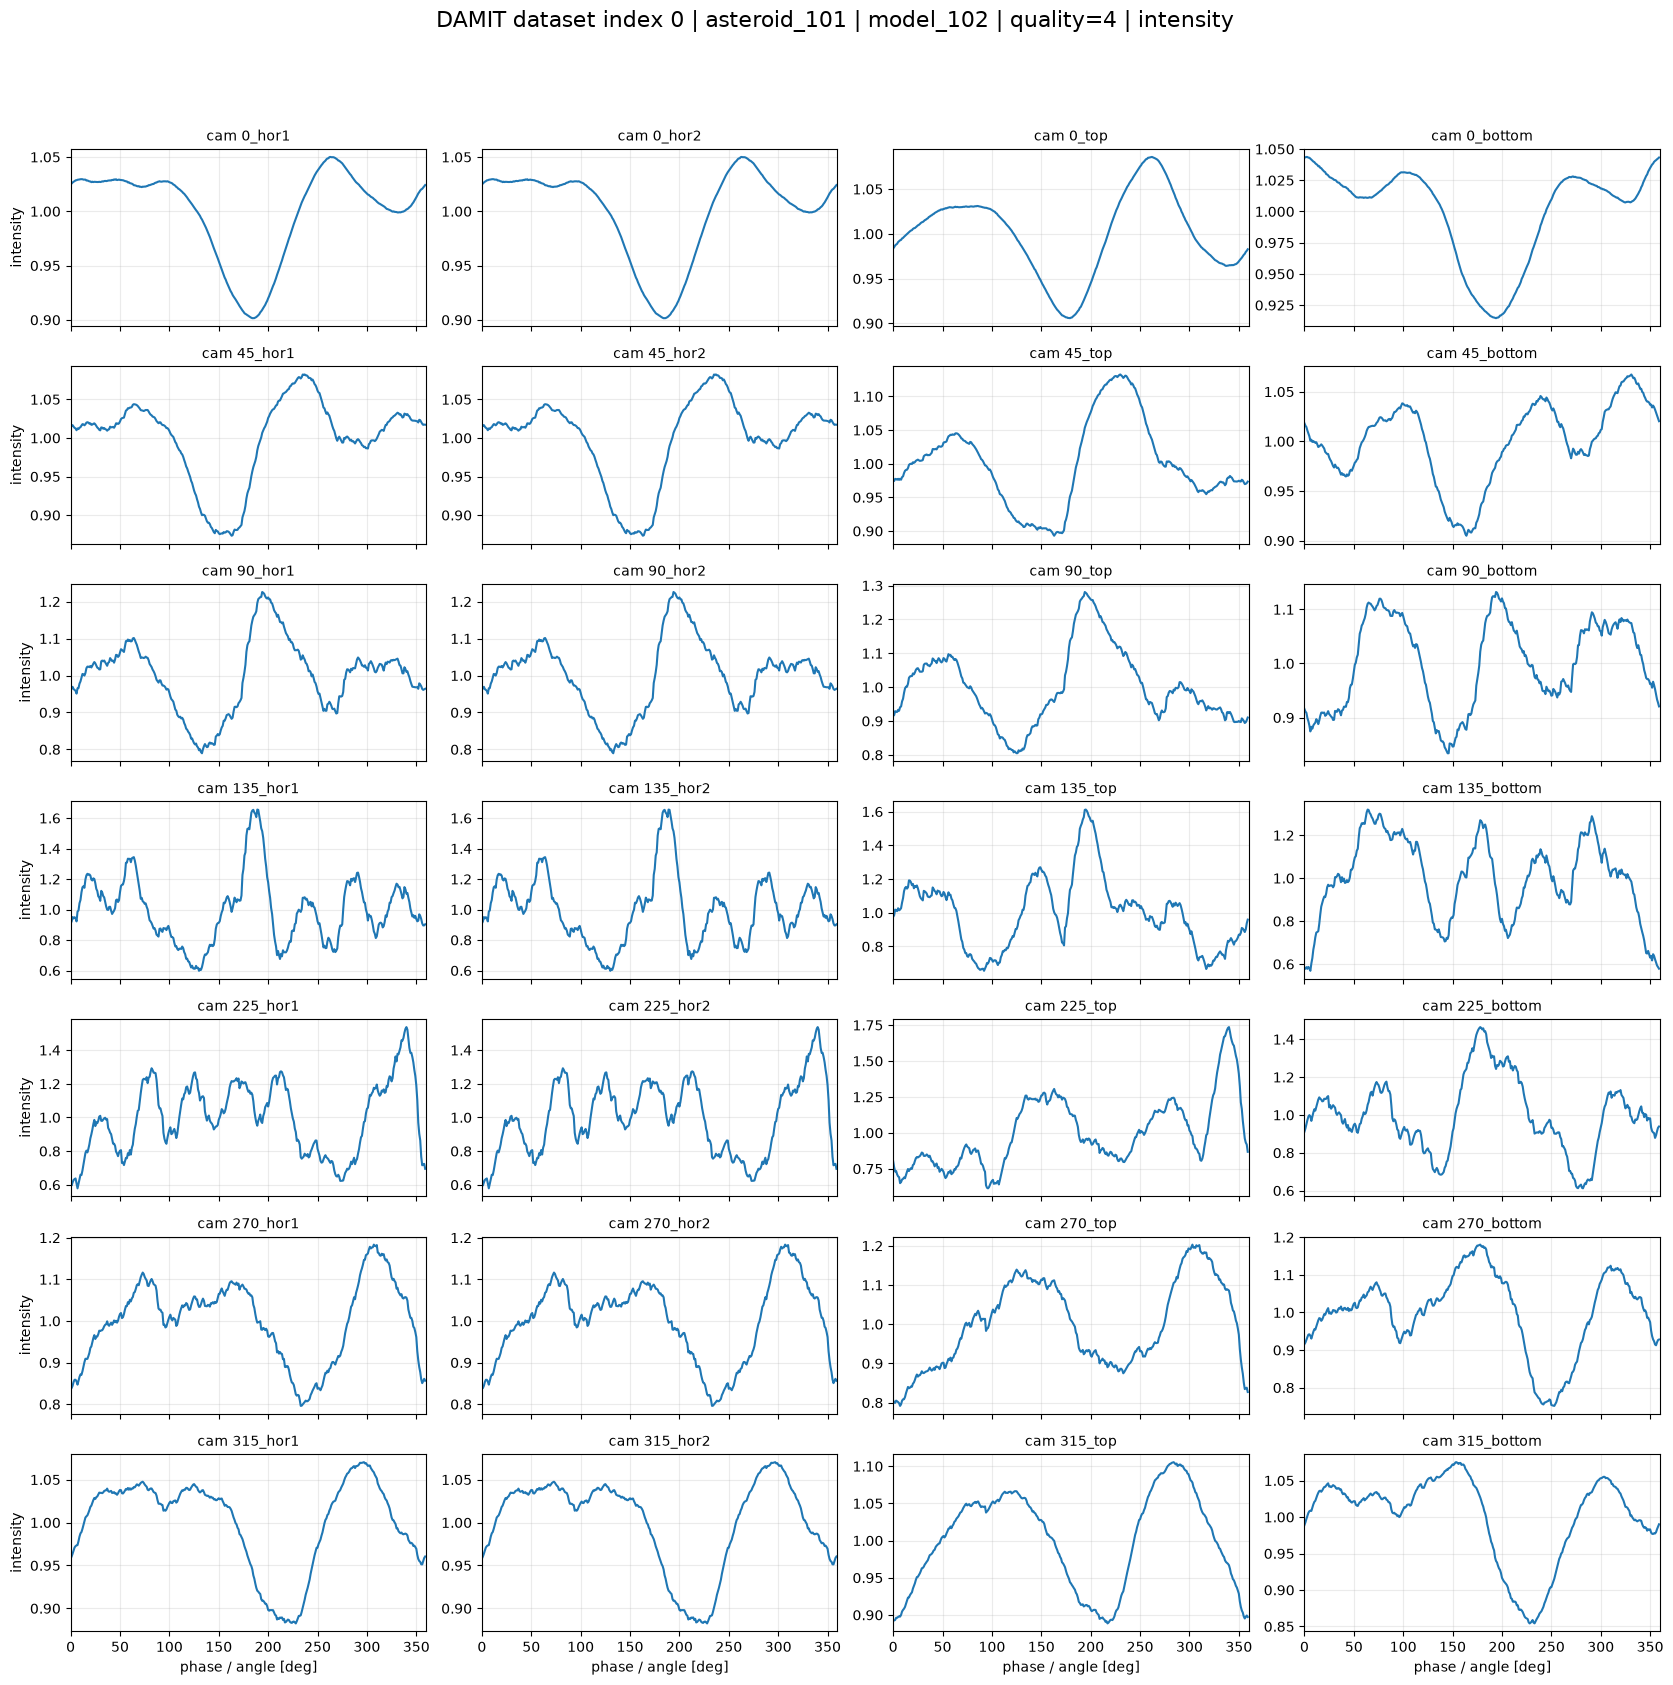

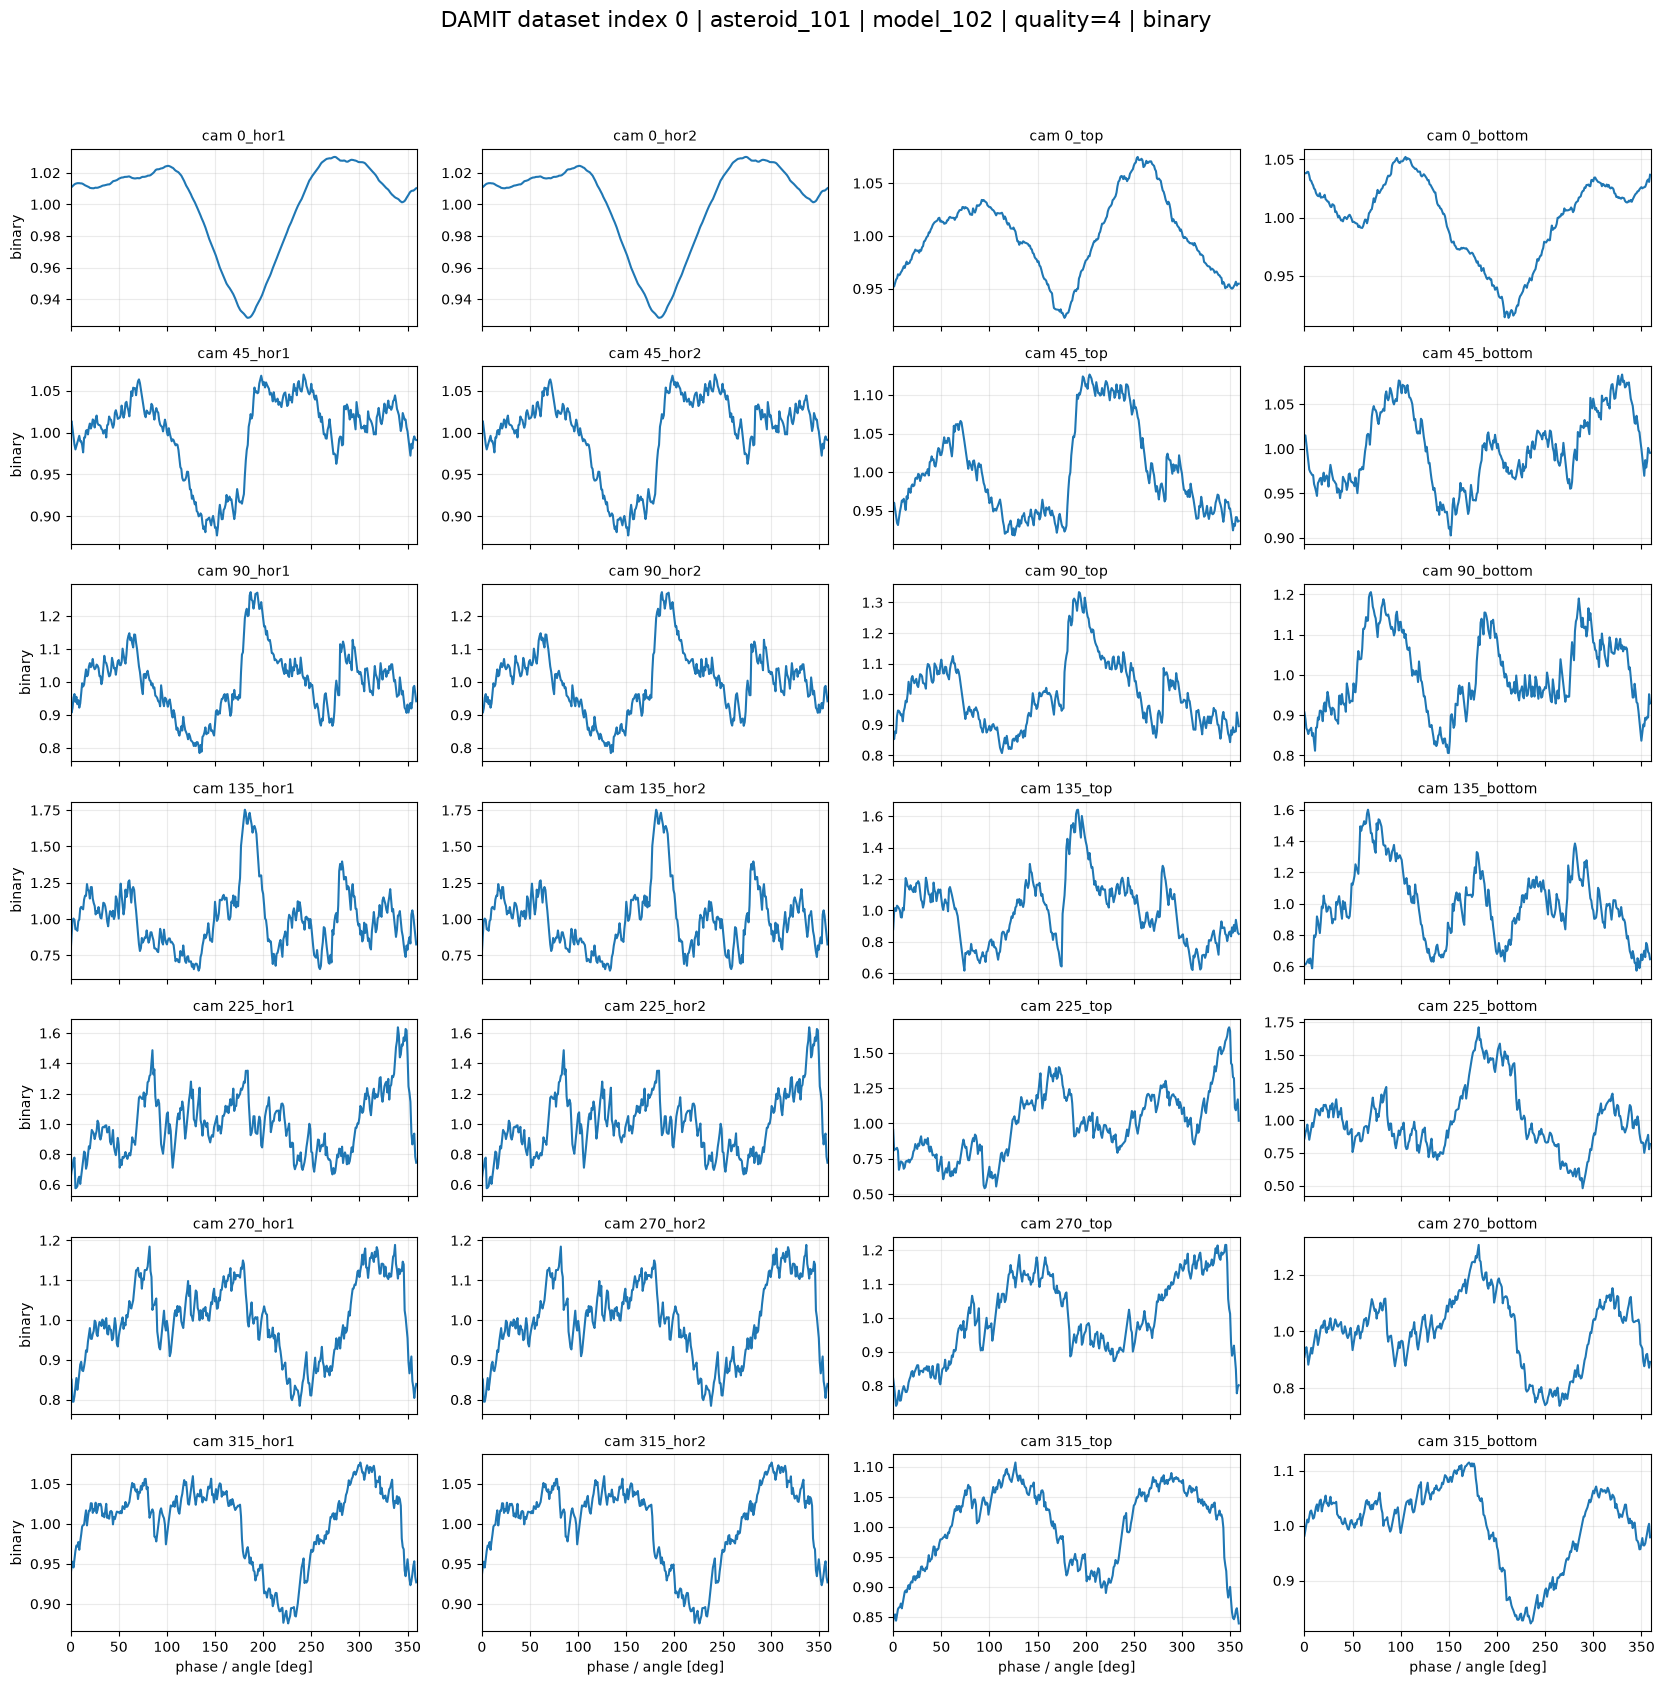

In [5]:
index = 0

plot_damit_lcs(
    dataset,
    index=index,
    cam_idx=POSITION_IDS,
    curve_type="intensity",
)

plot_damit_lcs(
    dataset,
    index=index,
    cam_idx=POSITION_IDS,
    curve_type="binary",
);

In [6]:
def show_damit_mesh(dataset, index, *, height=700):
    sample = dataset[index]
    mesh = sample["mesh"]

    v = np.asarray(mesh.vertices)
    f = np.asarray(mesh.faces)

    fig = go.Figure(
        data=[
            go.Mesh3d(
                x=v[:, 0],
                y=v[:, 1],
                z=v[:, 2],
                i=f[:, 0],
                j=f[:, 1],
                k=f[:, 2],
                color="lightgrey",
                flatshading=True,
                opacity=1.0,
                hoverinfo="skip",
                lighting=dict(
                    ambient=0.18,
                    diffuse=0.95,
                    specular=0.08,
                    roughness=0.95,
                    fresnel=0.02,
                ),
                lightposition=dict(
                    x=120,
                    y=160,
                    z=80,
                ),
            )
        ]
    )

    fig.update_layout(
        title=(
            f"DAMIT index {index} · "
            f"asteroid {sample['asteroid_id']} · "
            f"model {sample['model_id']}"
        ),
        scene=dict(
            aspectmode="data",
            xaxis=dict(visible=False),
            yaxis=dict(visible=False),
            zaxis=dict(visible=False),
            camera=dict(
                eye=dict(x=1.7, y=1.5, z=1.0),
            ),
        ),
        margin=dict(l=0, r=0, b=0, t=50),
        height=height,
    )

    fig.show()
    return fig

In [7]:
show_damit_mesh(dataset, index=0);

In [8]:
dataset.get_mesh_diagnostics(0)

{'index': 0,
 'asteroid_id': 101,
 'model_id': 102,
 'n_vertices': 402,
 'n_faces': 800,
 'x_bounds': (-1.120645546888029, 1.120645546888029),
 'y_bounds': (-1.0250344151793322, 1.0250344151793322),
 'z_bounds': (-1.0, 1.0),
 'max_xy_radius': 1.1487757797969544,
 'max_3d_radius': 1.2297589327090057,
 'camera_margin': 0.1,
 'camera_distance': 5.867228396617155}

2026-08-10 03:41:23.421 (  15.550s) [    7F6CE3BD7740]vtkXOpenGLRenderWindow.:1460  WARN| bad X server connection. DISPLAY=


Rendering 45_top:   0%|          | 0/8 [00:00<?, ?it/s]

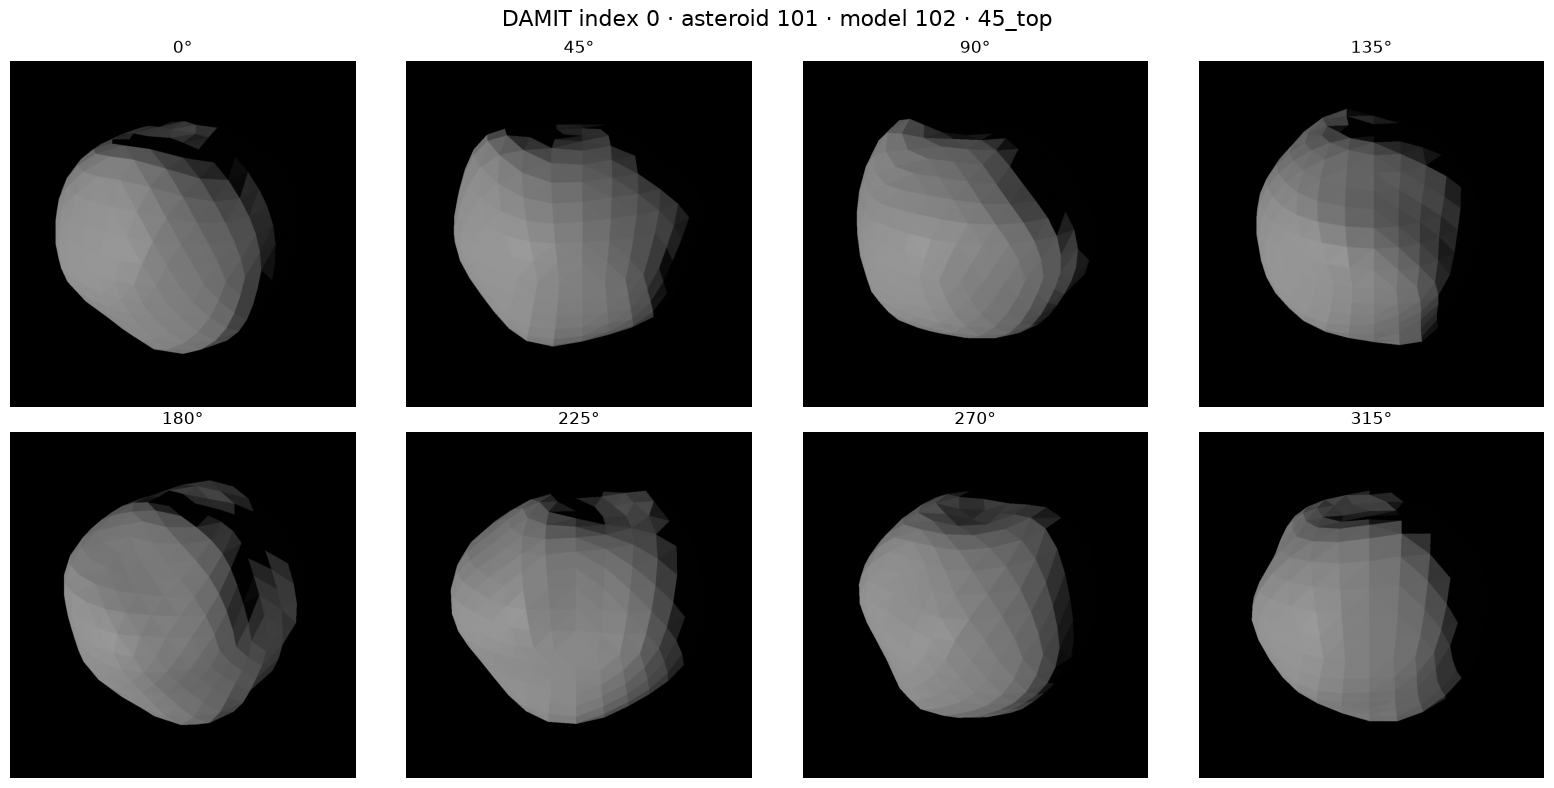

Rendering 45_top:   0%|          | 0/8 [00:00<?, ?it/s]

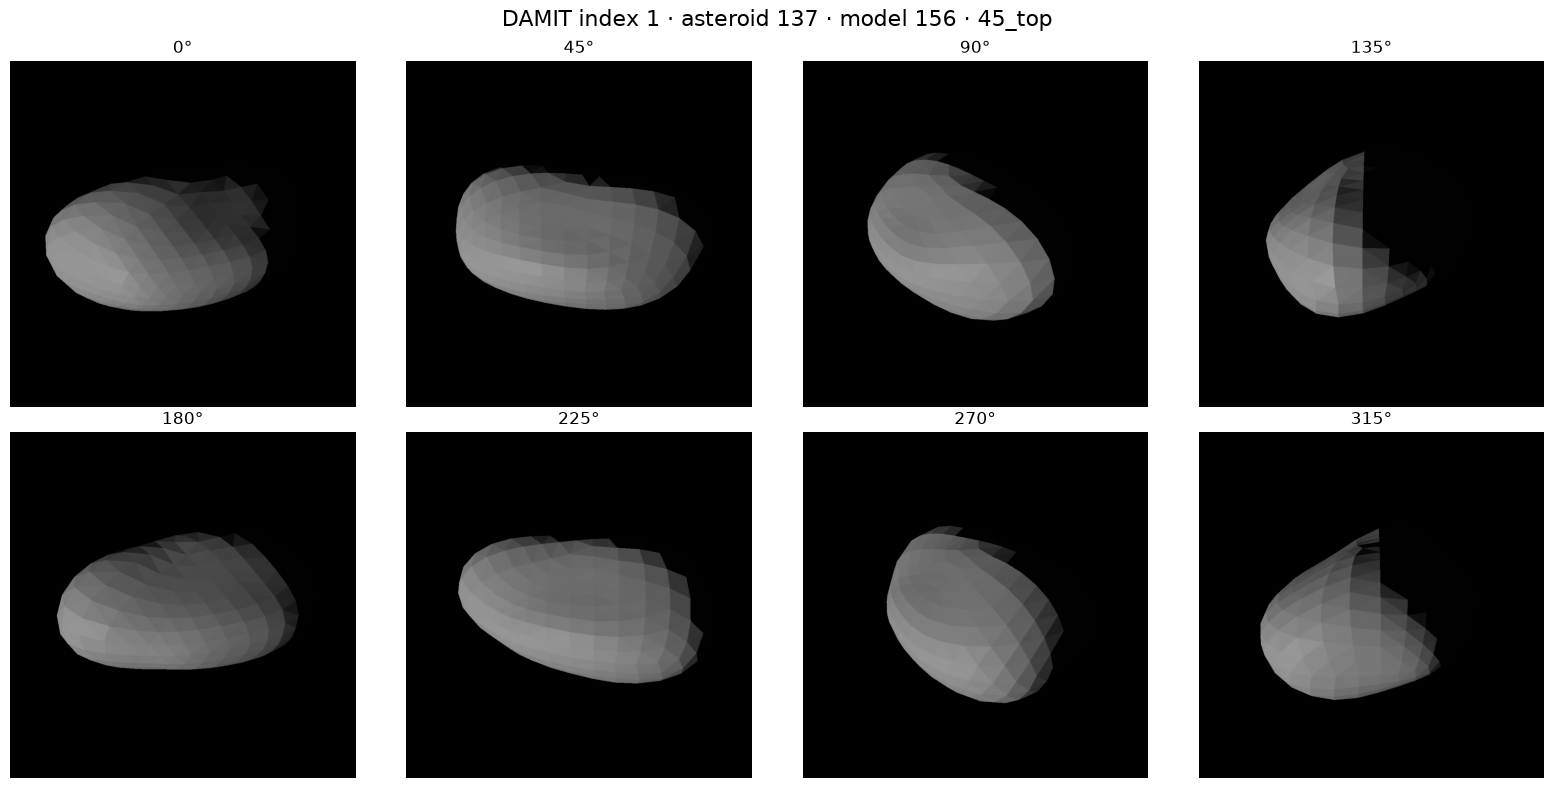

Rendering 45_top:   0%|          | 0/8 [00:00<?, ?it/s]

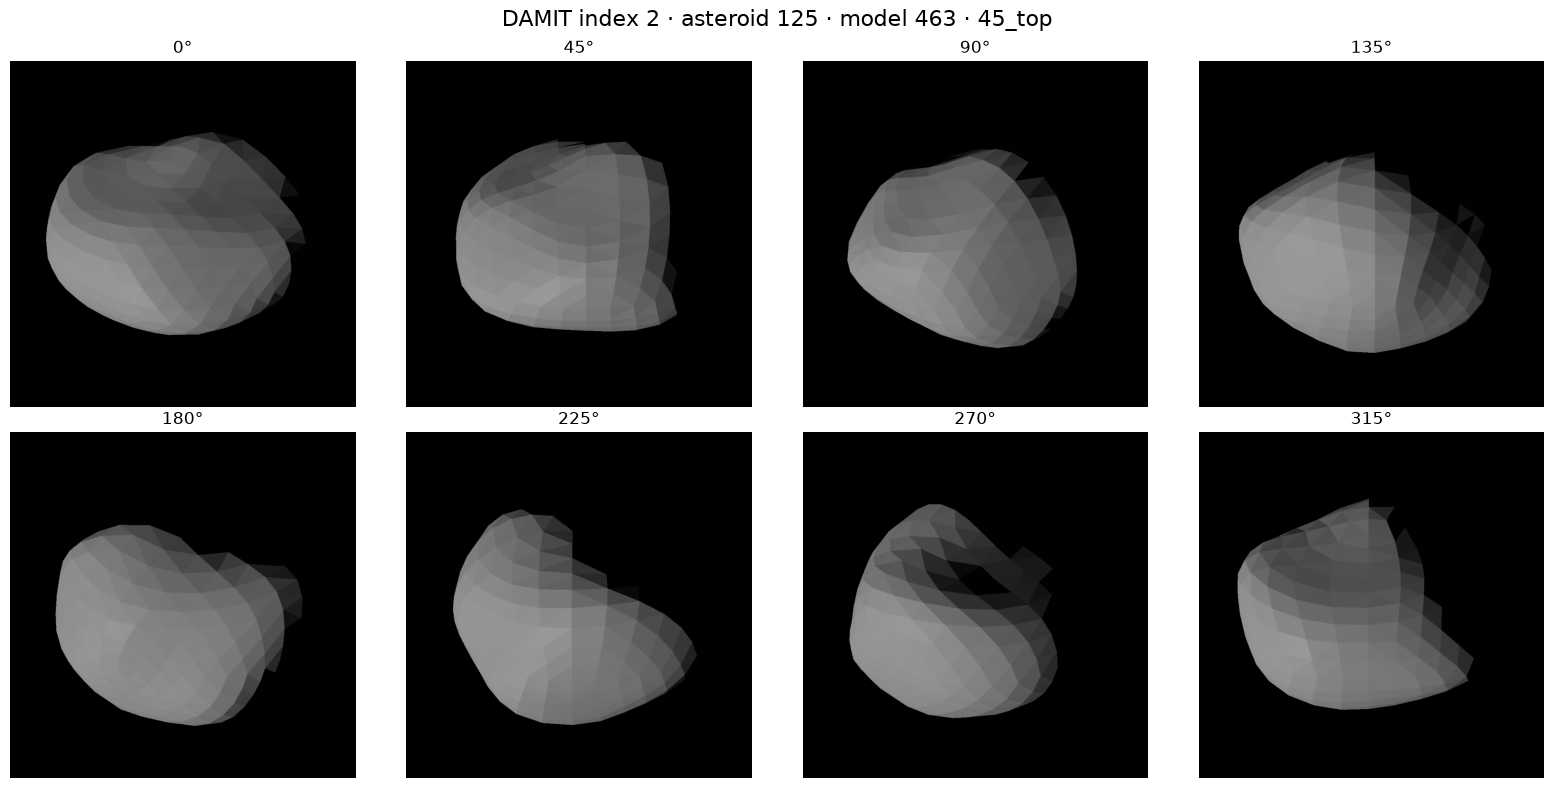

Rendering 45_top:   0%|          | 0/8 [00:00<?, ?it/s]

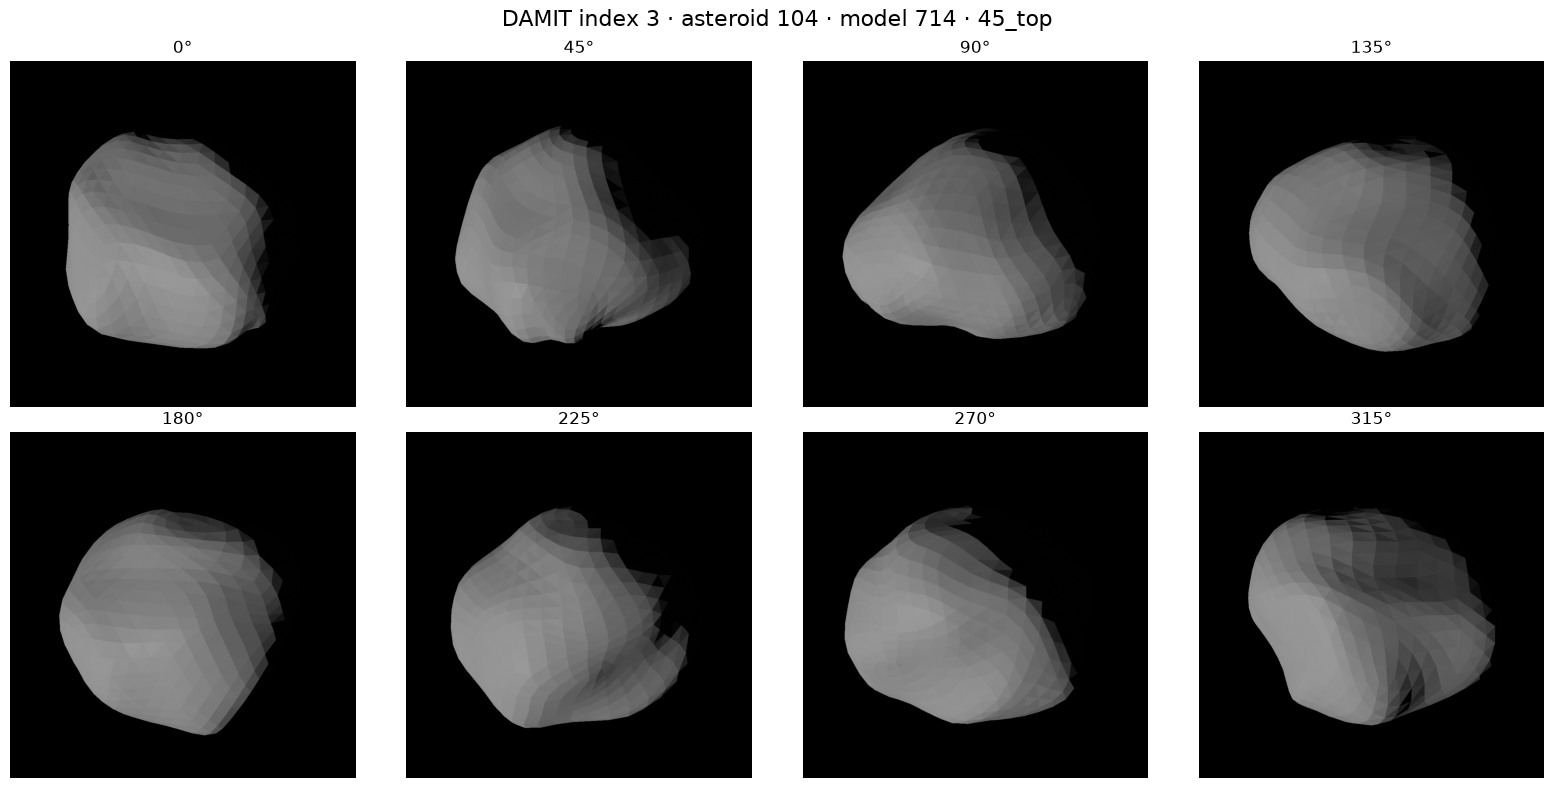

Rendering 45_top:   0%|          | 0/8 [00:00<?, ?it/s]

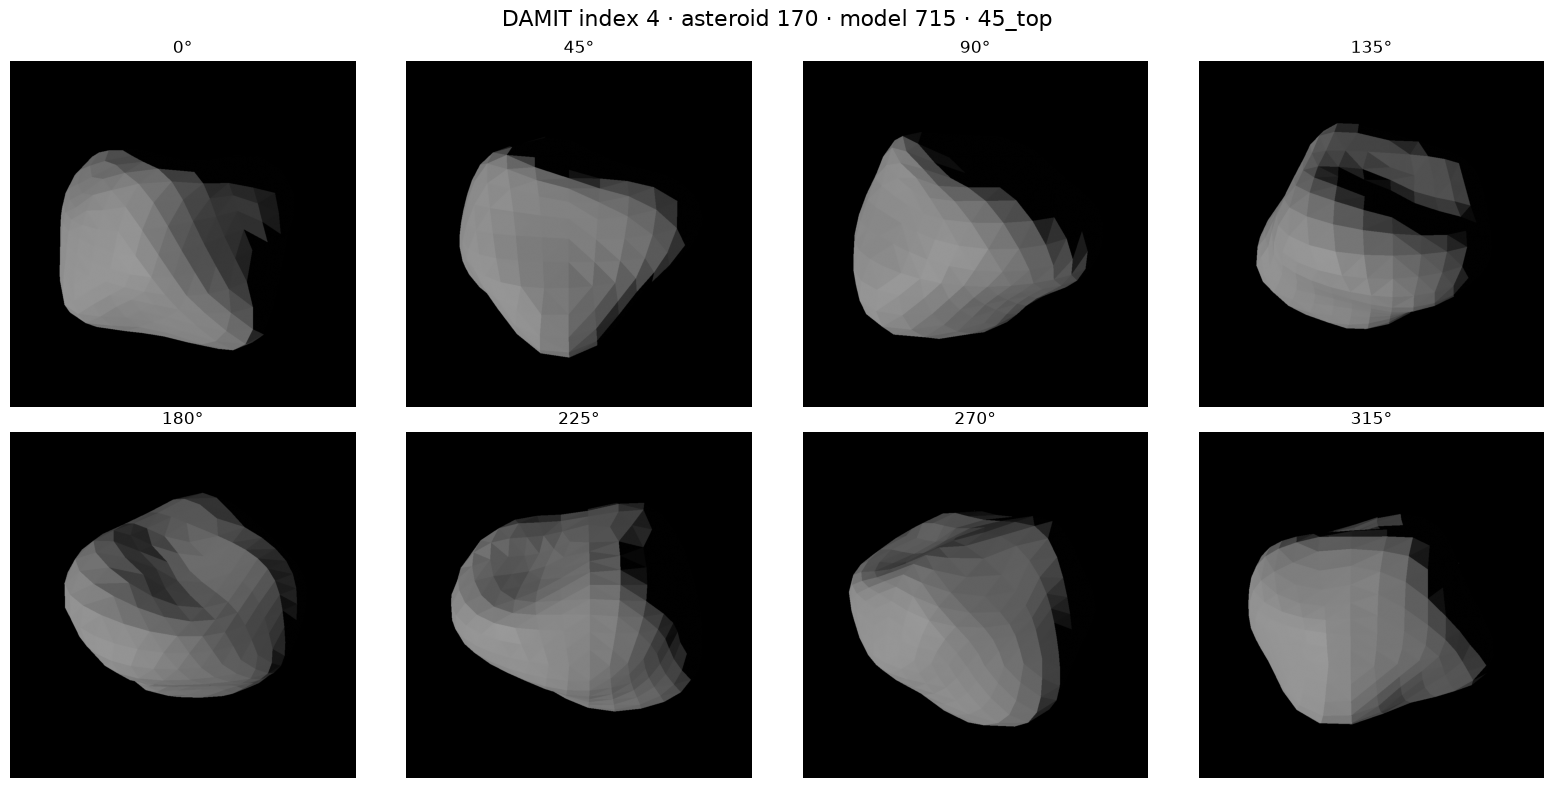

In [9]:
import math

import matplotlib.pyplot as plt
import numpy as np


n_asteroids = 5
cam_idx = "45_top"
n_angles = 8

rot_angles = np.linspace(
    0,
    360,
    n_angles,
    endpoint=False,
)

for index in range(
    min(n_asteroids, len(dataset))
):
    frames = dataset.render_validation_frames(
        index=index,
        cam_idx=cam_idx,
        rot_angles=rot_angles,
    )

    ncols = min(
        4,
        n_angles,
    )

    nrows = math.ceil(
        n_angles / ncols
    )

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(
            4 * ncols,
            4 * nrows,
        ),
        squeeze=False,
    )

    axes = axes.ravel()

    for ax, frame, angle in zip(
        axes,
        frames,
        rot_angles,
    ):
        ax.imshow(
            frame,
            cmap="gray",
            vmin=0,
            vmax=255,
        )

        ax.set_title(
            f"{angle:.0f}°"
        )

        ax.axis(
            "off"
        )

    for ax in axes[len(frames):]:
        ax.set_visible(
            False
        )

    row = dataset.models.iloc[
        index
    ]

    fig.suptitle(
        (
            f"DAMIT index {index} · "
            f"asteroid {int(row['asteroid_id'])} · "
            f"model {int(row['id'])} · "
            f"{cam_idx}"
        ),
        fontsize=16,
    )

    fig.tight_layout()

    plt.show()